# Pertemuan 5: Validasi, Ensemble, dan Ketidakseimbangan Kelas

Pertemuan 4 menghasilkan dua model terbaik:

| Model | Kelebihan pada data validasi Pertemuan 4 |
| --- | --- |
| Logistic Regression + TF-IDF | Macro F1 tertinggi; spam yang masuk kotak masuk paling sedikit. |
| Multinomial Naive Bayes + frekuensi kata (unigram + bigram) | Phish Recall tertinggi; email sah yang hilang paling sedikit. |

Notebook ini melanjutkan kedua model dalam lima langkah:

1. **Validasi silang dan tuning** untuk mengukur kestabilan hasil dan menyetel hyperparameter utama.
2. **Penanganan ketidakseimbangan kelas**, termasuk SMOTE.
3. **Model ensemble**: LightGBM dan stacking.
4. **Pergeseran threshold Ham** agar email sah sesedikit mungkin hilang.
5. **Analisis kesalahan** pada model terpilih.

Seluruh eksperimen hanya memakai data training. Data testing tetap disimpan untuk evaluasi akhir.

# A. Data

Dataset, preprocessing, dan pembagian data sama dengan Pertemuan 3 dan 4. Sel berikut memuat library dan dataset, menjalankan preprocessing, lalu menyisihkan data testing. Hanya data training (223.152 pesan) yang disimpan.

In [1]:
import sys
import subprocess
import os
import time
import gc

def ensure(package, module=None):
    try:
        __import__(module or package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

ensure('datasets')
ensure('imbalanced-learn', 'imblearn')
ensure('lightgbm')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import sklearn
import imblearn
import lightgbm as lgb
from datasets import load_dataset
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 42
DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
CLASS_IDS = [0, 1, 2]

raw_df = load_dataset(DATASET_NAME, split='train').to_pandas()
data = raw_df[['text', 'label']].dropna(subset=['text', 'label']).copy()
data = data[data['label'].isin(CLASS_IDS)].copy()
data['label'] = data['label'].astype(int)
data['clean_text'] = data['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
data = data[data['clean_text'].ne('')].copy()
data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
data = data.loc[~data['dedup_key'].isin(labels_per_key[labels_per_key.gt(1)].index)]
df_clean = (
    data.drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
del raw_df, data
gc.collect()

# Bagian testing (20%) tidak disimpan: data testing tidak dipakai pada notebook ini.
X_train, _, y_train, _ = train_test_split(
    df_clean['text'], df_clean['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df_clean['label']
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.to_numpy()
del df_clean
gc.collect()

print(f'Jumlah data training: {len(X_train):,} (Pertemuan 3: 223,152)')
print('Jumlah per kelas   :', {LABEL_NAMES[c]: int((y_train == c).sum()) for c in CLASS_IDS})
print(f'Versi library      : scikit-learn {sklearn.__version__}, imbalanced-learn {imblearn.__version__}, '
      f'lightgbm {lgb.__version__}, pandas {pd.__version__}, numpy {np.__version__}')

README.md:   0%|          | 0.00/990 [00:00<?, ?B/s]

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Jumlah data training: 223,152 (Pertemuan 3: 223,152)
Jumlah per kelas   : {'Ham': 102192, 'Phish': 34270, 'Spam': 86690}
Versi library      : scikit-learn 1.6.1, imbalanced-learn 0.14.2, lightgbm 4.6.0, pandas 2.2.3, numpy 2.4.6


# B. Prioritas Bisnis dan Metrik

## B.1 Prioritas Kesalahan

Kriteria sukses pada tahap Business Understanding menuntut tingkat *false positive* yang sangat rendah: email sah tidak boleh hilang. Karena itu, setiap jenis kesalahan diberi urutan prioritas:

| Prioritas | Kesalahan (aktual → prediksi) | Akibat | Sikap |
| ---: | --- | --- | --- |
| 1 | Ham → Spam, Ham → Phish | Email sah hilang dari kotak masuk. | Ditekan serendah mungkin. |
| 2 | Phish → Ham | Phishing masuk kotak masuk tanpa peringatan. | Dijaga tetap rendah. |
| 3 | Phish → Spam | Phishing tersaring, tetapi tanpa peringatan keamanan. | Dapat diterima. |
| 4 | Spam → Phish | Spam ditandai sebagai phishing. | Dapat diterima. |
| 5 | Spam → Ham | Spam masuk kotak masuk. | Kesalahan yang paling dapat diterima. |

Dengan kata lain, model boleh meloloskan sebagian spam ke kotak masuk asalkan email sah tidak hilang.

## B.2 Metrik dan Aturan Pemilihan

| Metrik | Arti |
| --- | --- |
| **Ham Recall** | Proporsi email sah yang tetap masuk kotak masuk. Metrik prioritas. |
| **Macro F1** | Rata-rata F1 ketiga kelas dengan bobot sama. |
| Phish Recall | Proporsi Phish yang dikenali sebagai Phish. |
| Phish Precision | Proporsi pesan berlabel Phish yang benar-benar Phish. |
| PR-AUC Phish | Kemampuan model menempatkan pesan Phish di atas pesan lain, tanpa bergantung pada threshold. |

Aturan pemilihan pada notebook ini:

1. Selama tuning dan eksperimen, konfigurasi dengan Macro F1 rata-rata tertinggi dipilih. Jika selisih Macro F1 kurang dari 0,001, dipilih konfigurasi dengan Ham Recall lebih tinggi.
2. Untuk model akhir, setiap kandidat disetel agar Ham Recall minimal **99,5%**, yaitu paling banyak 1 dari 200 email sah hilang (bagian G). Pada Ham Recall yang sama, model dengan Macro F1 tertinggi dipilih.

Sel berikut menyiapkan fungsi perhitungan metrik.

In [2]:
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score

HAM_RECALL_TARGET = 0.995
TIE_TOLERANCE = 0.001
METRICS = ['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision', 'PR-AUC Phish']
ERROR_PAIRS = [(0, 2), (0, 1), (1, 0), (1, 2), (2, 1), (2, 0)]  # urutan prioritas B.1
ERROR_LABELS = [f'{LABEL_NAMES[a]} → {LABEL_NAMES[p]}' for a, p in ERROR_PAIRS]


def compute_metrics(y_true, y_pred, phish_score):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    return {
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Ham Recall': cm[0, 0] / cm[0].sum(),
        'Phish Recall': cm[1, 1] / cm[1].sum(),
        'Phish Precision': cm[1, 1] / max(cm[:, 1].sum(), 1),
        'PR-AUC Phish': average_precision_score(y_true == 1, phish_score),
    }


def predict_with_ham_bias(log_proba, ham_bias=0.0):
    adjusted = log_proba.copy()
    adjusted[:, 0] += ham_bias
    return adjusted.argmax(axis=1)


def error_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    return {label: int(cm[a, p]) for label, (a, p) in zip(ERROR_LABELS, ERROR_PAIRS)}


def edge_note(best, grid):
    if best in (min(grid), max(grid)):
        return (' Nilai terbaik berada di ujung rentang yang diuji, sehingga nilai di luar rentang ini '
                'mungkin memberi hasil yang lebih baik.')
    return ''


def change_text(delta):
    if abs(delta) < TIE_TOLERANCE:
        return 'hampir tidak berubah'
    return f'naik {delta:.4f}' if delta > 0 else f'turun {abs(delta):.4f}'

# C. Strategi Validasi

## C.1 Stratified 5-Fold Cross-Validation

Model dievaluasi dengan *stratified 5-fold cross-validation* pada data training. Data training dibagi menjadi lima bagian (*fold*) dengan proporsi kelas yang sama. Setiap model dilatih lima kali. Pada setiap putaran, satu fold menjadi data validasi dan empat fold lainnya menjadi data latih. Hasil dilaporkan sebagai rata-rata ± simpangan baku dari lima putaran.

Validasi silang dipilih karena:

1. setiap pesan training dipakai tepat satu kali sebagai data validasi;
2. simpangan baku menunjukkan seberapa stabil hasil model;
3. data testing tetap tidak tersentuh.

Pencegahan *data leakage*:

| Risiko | Pencegahan |
| --- | --- |
| Vocabulary dan bobot IDF memakai informasi data validasi | Vectorizer dilatih ulang pada data latih setiap fold. |
| Resampling (oversampling, SMOTE, undersampling) memakai data validasi | Resampling hanya diterapkan pada data latih setiap fold. |
| Teks yang sama muncul di data latih dan data validasi | Duplikat sudah dihapus sebelum pembagian data. Sel berikut memeriksanya kembali pada setiap fold. |

## C.2 Persiapan Fold

Sel berikut membentuk lima fold, melatih dua vectorizer pada data latih setiap fold, lalu menyimpan matriks hasilnya ke disk. Matriks ini dipakai ulang oleh seluruh eksperimen, sehingga teks tidak perlu diproses ulang untuk setiap model.

| Representasi | Konfigurasi | Dipakai oleh |
| --- | --- | --- |
| Frekuensi kata (*count*) | unigram + bigram, `min_df=2` | Multinomial Naive Bayes dan LightGBM |
| TF-IDF | unigram, seluruh kosakata, `sublinear_tf=True` | Logistic Regression |

Langkah ini membutuhkan sekitar 20 menit dan sekitar 4 GB ruang disk.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

N_FOLDS = 5
CACHE_DIR = 'm05_cache'
os.makedirs(CACHE_DIR, exist_ok=True)
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))

fold_rows = []
for k, (tr, va) in enumerate(folds):
    start = time.perf_counter()
    text_tr, text_va = X_train.iloc[tr], X_train.iloc[va]

    count_vec = CountVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, dtype=np.float32)
    count_tr = count_vec.fit_transform(text_tr)
    sp.save_npz(f'{CACHE_DIR}/count_tr_{k}.npz', count_tr, compressed=False)
    sp.save_npz(f'{CACHE_DIR}/count_va_{k}.npz', count_vec.transform(text_va), compressed=False)
    unigram_mask = np.zeros(count_tr.shape[1], dtype=bool)
    for term, index in count_vec.vocabulary_.items():
        unigram_mask[index] = ' ' not in term
    np.save(f'{CACHE_DIR}/unigram_mask_{k}.npy', unigram_mask)
    n_count = count_tr.shape[1]
    del count_vec, count_tr
    gc.collect()

    tfidf_vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), sublinear_tf=True, dtype=np.float32)
    tfidf_tr = tfidf_vec.fit_transform(text_tr)
    sp.save_npz(f'{CACHE_DIR}/tfidf_tr_{k}.npz', tfidf_tr, compressed=False)
    sp.save_npz(f'{CACHE_DIR}/tfidf_va_{k}.npz', tfidf_vec.transform(text_va), compressed=False)
    n_tfidf = tfidf_tr.shape[1]
    del tfidf_vec, tfidf_tr
    gc.collect()

    fold_rows.append({
        'fold': k + 1,
        'data latih': len(tr),
        'data validasi': len(va),
        **{f'{LABEL_NAMES[c]} (validasi)': int((y_train[va] == c).sum()) for c in CLASS_IDS},
        'fitur count': n_count,
        'fitur TF-IDF': n_tfidf,
        'teks sama di latih dan validasi': len(set(text_tr.str.lower()) & set(text_va.str.lower())),
        'waktu (detik)': round(time.perf_counter() - start, 1),
    })
display(pd.DataFrame(fold_rows))

,fold,data latih,data validasi,Ham (validasi),Phish (validasi),Spam (validasi),fitur count,fitur TF-IDF,teks sama di latih dan validasi,waktu (detik)
0,1,178521,44631,20439,6854,17338,3382411,662933,0,208.4
1,2,178521,44631,20439,6854,17338,3149195,652462,0,228.9
2,3,178522,44630,20438,6854,17338,3350750,664719,0,228.2
3,4,178522,44630,20438,6854,17338,3336606,606059,0,239.6
4,5,178522,44630,20438,6854,17338,3347813,641424,0,239.9


Sel berikut menyiapkan fungsi validasi silang. Fungsi `run_cv` melatih satu konfigurasi pada lima fold, menyimpan prediksi setiap pesan training saat pesan tersebut menjadi data validasi (*out-of-fold*), dan menghitung metrik setiap fold.

In [4]:
cv_results = {}


def load_fold(k, representation):
    tr, va = folds[k]
    X_tr = sp.load_npz(f'{CACHE_DIR}/{representation}_tr_{k}.npz')
    X_va = sp.load_npz(f'{CACHE_DIR}/{representation}_va_{k}.npz')
    return X_tr, y_train[tr], X_va


def run_cv(name, representation, fit_predict, configuration):
    # fit_predict(X_tr, y_tr, X_va, k) mengembalikan log-probabilitas data validasi (n × 3).
    log_proba = np.zeros((len(y_train), 3))
    fold_scores = []
    start = time.perf_counter()
    for k, (tr, va) in enumerate(folds):
        X_tr, y_tr, X_va = load_fold(k, representation)
        log_proba[va] = fit_predict(X_tr, y_tr, X_va, k)
        fold_scores.append(compute_metrics(y_train[va], log_proba[va].argmax(axis=1), log_proba[va, 1]))
        del X_tr, X_va
        gc.collect()
    cv_results[name] = {
        'log_proba': log_proba,
        'folds': pd.DataFrame(fold_scores),
        'konfigurasi': configuration,
        'menit': (time.perf_counter() - start) / 60,
    }


def mean_metric(name, metric, ham_bias=0.0):
    if ham_bias == 0.0:
        return cv_results[name]['folds'][metric].mean()
    return per_fold_metrics(name, ham_bias)[metric].mean()


def per_fold_metrics(name, ham_bias=0.0):
    log_proba = cv_results[name]['log_proba']
    return pd.DataFrame([
        compute_metrics(y_train[va], predict_with_ham_bias(log_proba[va], ham_bias), log_proba[va, 1])
        for _, va in folds
    ])


def summary_table(names, ham_biases=None):
    rows = []
    for name in names:
        bias = (ham_biases or {}).get(name, 0.0)
        scores = per_fold_metrics(name, bias)
        row = {'model': name, 'konfigurasi': cv_results[name]['konfigurasi']}
        for metric in METRICS:
            row[metric] = f'{scores[metric].mean():.4f} ± {scores[metric].std(ddof=0):.4f}'
        row['waktu (menit)'] = round(cv_results[name]['menit'], 1)
        rows.append(row)
    return pd.DataFrame(rows)


def pick_best(names):
    table = pd.DataFrame({
        'model': names,
        'Macro F1': [mean_metric(n, 'Macro F1') for n in names],
        'Ham Recall': [mean_metric(n, 'Ham Recall') for n in names],
    })
    close = table[table['Macro F1'] >= table['Macro F1'].max() - TIE_TOLERANCE]
    return close.sort_values('Ham Recall', ascending=False).iloc[0]['model']


def mnb_fit_predict(alpha, sampler=None, balanced_weight=False):
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.utils.class_weight import compute_sample_weight

    def fit_predict(X_tr, y_tr, X_va, k):
        if sampler is not None:
            X_tr, y_tr = sampler(y_tr).fit_resample(X_tr, y_tr)
        weight = compute_sample_weight('balanced', y_tr) if balanced_weight else None
        model = MultinomialNB(alpha=alpha).fit(X_tr, y_tr, sample_weight=weight)
        return model.predict_log_proba(X_va)
    return fit_predict


def lr_fit_predict(C, class_weight=None):
    from sklearn.linear_model import LogisticRegression

    def fit_predict(X_tr, y_tr, X_va, k):
        model = LogisticRegression(C=C, class_weight=class_weight, max_iter=1000, random_state=RANDOM_STATE)
        model.fit(X_tr, y_tr)
        return model.predict_log_proba(X_va)
    return fit_predict

# D. Tuning Model Dasar

## D.1 Multinomial Naive Bayes: `alpha`

`alpha` mengatur besar *Laplace smoothing*. Pertemuan 4 (D.3) menunjukkan bahwa smoothing yang terlalu besar dibandingkan total bobot suatu kelas membuat kata-kata khas kelas tersebut kehilangan pengaruh. Sel berikut menguji lima nilai `alpha` pada frekuensi kata unigram + bigram.

| Parameter | Nilai yang diuji | Metode pencarian | Validasi |
| --- | --- | --- | --- |
| `alpha` | 0,01; 0,03; 0,1; 0,3; 1,0 | *Grid search* | Stratified 5-fold CV |

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB (alpha=0.01),"count unigram + bigram, alpha=0.01",0.9357 ± 0.0012,0.9930 ± 0.0003,0.9065 ± 0.0048,0.8832 ± 0.0025,0.9155 ± 0.0020,0.3
1,MNB (alpha=0.03),"count unigram + bigram, alpha=0.03",0.9368 ± 0.0013,0.9922 ± 0.0005,0.9206 ± 0.0052,0.8754 ± 0.0033,0.9160 ± 0.0016,0.2
2,MNB (alpha=0.1),"count unigram + bigram, alpha=0.1",0.9376 ± 0.0009,0.9908 ± 0.0003,0.9384 ± 0.0046,0.8647 ± 0.0030,0.9185 ± 0.0015,0.2
3,MNB (alpha=0.3),"count unigram + bigram, alpha=0.3",0.9398 ± 0.0009,0.9897 ± 0.0002,0.9572 ± 0.0030,0.8605 ± 0.0035,0.9232 ± 0.0010,0.2
4,MNB (alpha=1.0),"count unigram + bigram, alpha=1.0",0.9441 ± 0.0008,0.9897 ± 0.0004,0.9598 ± 0.0044,0.8815 ± 0.0050,0.9346 ± 0.0016,0.2


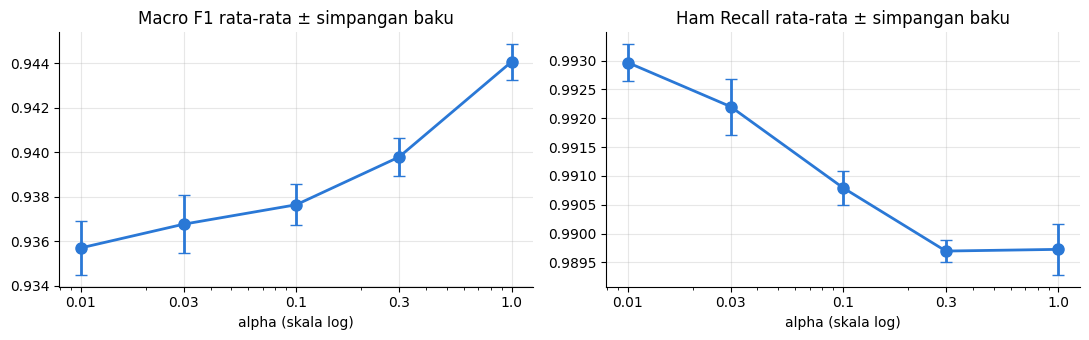

`alpha` terbaik adalah **1.0**, yaitu nilai bawaan. Nilai terbaik berada di ujung rentang yang diuji, sehingga nilai di luar rentang ini mungkin memberi hasil yang lebih baik.

In [5]:
ALPHA_GRID = [0.01, 0.03, 0.1, 0.3, 1.0]
mnb_names = []
for alpha in ALPHA_GRID:
    name = f'MNB (alpha={alpha})'
    run_cv(name, 'count', mnb_fit_predict(alpha), f'count unigram + bigram, alpha={alpha}')
    mnb_names.append(name)

display(summary_table(mnb_names))
BEST_MNB = pick_best(mnb_names)
BEST_ALPHA = ALPHA_GRID[mnb_names.index(BEST_MNB)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric in zip(axes, ['Macro F1', 'Ham Recall']):
    means = [mean_metric(n, metric) for n in mnb_names]
    stds = [cv_results[n]['folds'][metric].std(ddof=0) for n in mnb_names]
    ax.errorbar(ALPHA_GRID, means, yerr=stds, marker='o', markersize=8, linewidth=2, color='#2a78d6', capsize=4)
    ax.set_xscale('log')
    ax.set_xticks(ALPHA_GRID, [str(a) for a in ALPHA_GRID])
    ax.set_xlabel('alpha (skala log)')
    ax.set_title(f'{metric} rata-rata ± simpangan baku')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

if BEST_ALPHA == 1.0:
    alpha_text = '`alpha` terbaik adalah **1.0**, yaitu nilai bawaan.'
else:
    alpha_text = (
        f"`alpha` terbaik adalah **{BEST_ALPHA}**. Dibandingkan nilai bawaan `alpha=1.0`, Macro F1 "
        f"{change_text(mean_metric(BEST_MNB, 'Macro F1') - mean_metric('MNB (alpha=1.0)', 'Macro F1'))} "
        f"dan Ham Recall {change_text(mean_metric(BEST_MNB, 'Ham Recall') - mean_metric('MNB (alpha=1.0)', 'Ham Recall'))}."
    )
display(Markdown(alpha_text + edge_note(BEST_ALPHA, ALPHA_GRID)))

## D.2 Logistic Regression: `C`

`C` mengatur kekuatan regularisasi. Nilai `C` kecil membuat bobot kata lebih kecil dan model lebih sederhana; nilai `C` besar membuat model lebih mengikuti data training. Sel berikut menguji empat nilai `C` pada TF-IDF unigram. Langkah ini membutuhkan sekitar 50 menit.

| Parameter | Nilai yang diuji | Metode pencarian | Validasi |
| --- | --- | --- | --- |
| `C` | 1; 4; 16; 64 | *Grid search* | Stratified 5-fold CV |

In [6]:
C_GRID = [1, 4, 16, 64]
lr_names = []
for C in C_GRID:
    name = f'LR (C={C})'
    run_cv(name, 'tfidf', lr_fit_predict(C), f'TF-IDF unigram, C={C}')
    lr_names.append(name)

display(summary_table(lr_names))
BEST_LR = pick_best(lr_names)
BEST_C = C_GRID[lr_names.index(BEST_LR)]
if BEST_C == 1:
    c_text = '`C` terbaik adalah **1**, yaitu nilai bawaan.'
else:
    c_text = (
        f"`C` terbaik adalah **{BEST_C}**. Dibandingkan nilai bawaan `C=1`, Macro F1 "
        f"{change_text(mean_metric(BEST_LR, 'Macro F1') - mean_metric('LR (C=1)', 'Macro F1'))} "
        f"dan Ham Recall {change_text(mean_metric(BEST_LR, 'Ham Recall') - mean_metric('LR (C=1)', 'Ham Recall'))}."
    )
display(Markdown(c_text + edge_note(BEST_C, C_GRID)))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,LR (C=1),"TF-IDF unigram, C=1",0.9640 ± 0.0010,0.9787 ± 0.0010,0.9274 ± 0.0047,0.9673 ± 0.0015,0.9918 ± 0.0005,6.8
1,LR (C=4),"TF-IDF unigram, C=4",0.9669 ± 0.0006,0.9830 ± 0.0010,0.9374 ± 0.0024,0.9612 ± 0.0029,0.9923 ± 0.0004,6.9
2,LR (C=16),"TF-IDF unigram, C=16",0.9682 ± 0.0007,0.9855 ± 0.0020,0.9402 ± 0.0035,0.9587 ± 0.0019,0.9921 ± 0.0005,9.0
3,LR (C=64),"TF-IDF unigram, C=64",0.9687 ± 0.0011,0.9865 ± 0.0009,0.9425 ± 0.0020,0.9582 ± 0.0020,0.9925 ± 0.0004,9.1


`C` terbaik adalah **64**. Dibandingkan nilai bawaan `C=1`, Macro F1 naik 0.0046 dan Ham Recall naik 0.0079. Nilai terbaik berada di ujung rentang yang diuji, sehingga nilai di luar rentang ini mungkin memberi hasil yang lebih baik.

# E. Ketidakseimbangan Kelas

## E.1 Rasio Kelas

Sel berikut menampilkan jumlah pesan per kelas pada data training dan rasio setiap kelas terhadap Phish.

In [7]:
class_counts = pd.Series({LABEL_NAMES[c]: int((y_train == c).sum()) for c in CLASS_IDS})
display(pd.DataFrame({
    'jumlah pesan': class_counts,
    'persentase': (class_counts / class_counts.sum() * 100).round(2),
    'rasio terhadap Phish': (class_counts / class_counts['Phish']).round(2),
}))

,jumlah pesan,persentase,rasio terhadap Phish
Ham,102192,45.79,2.98
Phish,34270,15.36,1.00
Spam,86690,38.85,2.53


## E.2 Teknik yang Diuji

Teknik berikut diuji pada Multinomial Naive Bayes dengan `alpha` terbaik dari D.1. Logistic Regression diuji dengan bobot kelas sebagai pembanding. Seluruh resampling hanya diterapkan pada data latih setiap fold.

| Teknik | Cara kerja | Konfigurasi |
| --- | --- | --- |
| Tanpa penanganan | Data latih dipakai apa adanya. | — |
| Bobot kelas | Setiap pesan diberi bobot berbanding terbalik dengan jumlah pesan kelasnya, sehingga ketiga kelas berpengaruh sama. | `sample_weight='balanced'` (MNB), `class_weight='balanced'` (LR) |
| Random oversampling | Pesan Phish diduplikasi secara acak. | Phish ditambah sampai sama dengan jumlah Ham |
| SMOTE | Pesan Phish sintetis dibuat di antara satu pesan Phish dan salah satu dari lima tetangga Phish terdekatnya. | Phish ditambah sampai sama dengan jumlah Ham; `k_neighbors=5` |
| Random undersampling | Pesan Ham dan Spam dibuang secara acak. | Ham dan Spam dikurangi sampai sama dengan jumlah Phish |

Pergeseran threshold dibahas terpisah pada bagian G, karena threshold pada notebook ini diarahkan untuk melindungi email sah.

Langkah ini membutuhkan sekitar 30 menit.

In [8]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler


def phish_up_to_ham(y):
    return {1: int((y == 0).sum())}


IMB_NONE_MNB = BEST_MNB
IMB_WEIGHT_MNB = 'MNB + bobot kelas'
IMB_ROS_MNB = 'MNB + random oversampling'
IMB_SMOTE_MNB = 'MNB + SMOTE'
IMB_RUS_MNB = 'MNB + random undersampling'
IMB_NONE_LR = BEST_LR
IMB_WEIGHT_LR = 'LR + bobot kelas'

run_cv(IMB_WEIGHT_MNB, 'count', mnb_fit_predict(BEST_ALPHA, balanced_weight=True), f'alpha={BEST_ALPHA}, bobot kelas')
run_cv(IMB_ROS_MNB, 'count',
       mnb_fit_predict(BEST_ALPHA, sampler=lambda y: RandomOverSampler(
           sampling_strategy=phish_up_to_ham(y), random_state=RANDOM_STATE)),
       f'alpha={BEST_ALPHA}, Phish = Ham')
run_cv(IMB_SMOTE_MNB, 'count',
       mnb_fit_predict(BEST_ALPHA, sampler=lambda y: SMOTE(
           sampling_strategy=phish_up_to_ham(y), k_neighbors=5, random_state=RANDOM_STATE)),
       f'alpha={BEST_ALPHA}, Phish = Ham, k_neighbors=5')
run_cv(IMB_RUS_MNB, 'count',
       mnb_fit_predict(BEST_ALPHA, sampler=lambda y: RandomUnderSampler(
           sampling_strategy='not minority', random_state=RANDOM_STATE)),
       f'alpha={BEST_ALPHA}, Ham = Spam = Phish')
run_cv(IMB_WEIGHT_LR, 'tfidf', lr_fit_predict(BEST_C, class_weight='balanced'), f'C={BEST_C}, bobot kelas')

## E.3 Hasil

Tabel berikut mengikuti format *TP vs alarm palsu* untuk kelas Phish. TP, FP, dan FN dijumlahkan dari seluruh fold, sehingga mencakup seluruh 223.152 pesan training. Kolom *Ham hilang* menunjukkan jumlah email sah yang diprediksi sebagai Spam atau Phish.

In [9]:
IMB_TECHNIQUES = [
    ('Multinomial Naive Bayes', 'Tanpa penanganan', IMB_NONE_MNB),
    ('Multinomial Naive Bayes', 'Bobot kelas', IMB_WEIGHT_MNB),
    ('Multinomial Naive Bayes', 'Random oversampling', IMB_ROS_MNB),
    ('Multinomial Naive Bayes', 'SMOTE', IMB_SMOTE_MNB),
    ('Multinomial Naive Bayes', 'Random undersampling', IMB_RUS_MNB),
    ('Logistic Regression', 'Tanpa penanganan', IMB_NONE_LR),
    ('Logistic Regression', 'Bobot kelas', IMB_WEIGHT_LR),
]
imb_rows = []
for algorithm, technique, name in IMB_TECHNIQUES:
    y_pred = cv_results[name]['log_proba'].argmax(axis=1)
    cm = confusion_matrix(y_train, y_pred, labels=CLASS_IDS)
    scores = cv_results[name]['folds']
    imb_rows.append({
        'model': algorithm,
        'teknik': technique,
        'TP': int(cm[1, 1]),
        'FP': int(cm[:, 1].sum() - cm[1, 1]),
        'FN': int(cm[1].sum() - cm[1, 1]),
        'Phish Recall': scores['Phish Recall'].mean(),
        'Phish Precision': scores['Phish Precision'].mean(),
        'Phish F1': f1_score(y_train == 1, y_pred == 1),
        'PR-AUC Phish': scores['PR-AUC Phish'].mean(),
        'Ham hilang': int(cm[0, 1] + cm[0, 2]),
        'Ham Recall': scores['Ham Recall'].mean(),
        'Macro F1': f"{scores['Macro F1'].mean():.4f} ± {scores['Macro F1'].std(ddof=0):.4f}",
    })
imb_table = pd.DataFrame(imb_rows)
display(imb_table.round(4))

,model,teknik,TP,FP,FN,Phish Recall,Phish Precision,Phish F1,PR-AUC Phish,Ham hilang,Ham Recall,Macro F1
0,Multinomial Naive Bayes,Tanpa penanganan,32894,4422,1376,0.9598,0.8815,0.9190,0.9346,1050,0.9897,0.9441 ± 0.0008
1,Multinomial Naive Bayes,Bobot kelas,33046,6210,1224,0.9643,0.8418,0.8989,0.9269,1201,0.9882,0.9353 ± 0.0010
2,Multinomial Naive Bayes,Random oversampling,32800,5925,1470,0.9571,0.8470,0.8987,0.9254,1150,0.9887,0.9350 ± 0.0007
3,Multinomial Naive Bayes,SMOTE,32571,5305,1699,0.9504,0.8600,0.9029,0.9308,1102,0.9892,0.9371 ± 0.0006
4,Multinomial Naive Bayes,Random undersampling,33261,6091,1009,0.9706,0.8452,0.9036,0.9290,1342,0.9869,0.9328 ± 0.0013
5,Logistic Regression,Tanpa penanganan,32298,1409,1972,0.9425,0.9582,0.9503,0.9925,1376,0.9865,0.9687 ± 0.0011
6,Logistic Regression,Bobot kelas,32735,1794,1535,0.9552,0.9480,0.9516,0.9927,1529,0.9850,0.9691 ± 0.0006


## E.4 Keputusan

Teknik dipilih per model dengan aturan berikut: teknik dengan Macro F1 rata-rata tertinggi dipilih, asalkan Ham Recall tidak turun lebih dari 0,001 dibandingkan tanpa penanganan. Aturan ini menjaga prioritas B.1: penanganan ketidakseimbangan tidak boleh membuat lebih banyak email sah hilang.

In [10]:
def choose_technique(options):
    base_ham = mean_metric(options[0][1], 'Ham Recall')
    allowed = [(t, n) for t, n in options if mean_metric(n, 'Ham Recall') >= base_ham - TIE_TOLERANCE]
    return max(allowed, key=lambda item: mean_metric(item[1], 'Macro F1'))

mnb_options = [(t, n) for a, t, n in IMB_TECHNIQUES if a == 'Multinomial Naive Bayes']
lr_options = [(t, n) for a, t, n in IMB_TECHNIQUES if a == 'Logistic Regression']
MNB_TECHNIQUE, FINAL_MNB = choose_technique(mnb_options)
LR_TECHNIQUE, FINAL_LR = choose_technique(lr_options)

phish_gain = {t: mean_metric(n, 'Phish Recall') - mean_metric(IMB_NONE_MNB, 'Phish Recall') for t, n in mnb_options[1:]}
balancing_helps = max(phish_gain['Bobot kelas'], phish_gain['Random oversampling']) > 0.01
smote_f1 = mean_metric(IMB_SMOTE_MNB, 'Macro F1') - mean_metric(IMB_NONE_MNB, 'Macro F1')
smote_ham = mean_metric(IMB_SMOTE_MNB, 'Ham Recall') - mean_metric(IMB_NONE_MNB, 'Ham Recall')

imbalance_text = f'''
- **Multinomial Naive Bayes:** teknik terpilih adalah **{MNB_TECHNIQUE.lower()}**.
- **Logistic Regression:** teknik terpilih adalah **{LR_TECHNIQUE.lower()}**.
- **SMOTE** pada Multinomial Naive Bayes membuat Macro F1 {change_text(smote_f1)} dan Ham Recall {change_text(smote_ham)} dibandingkan tanpa penanganan.
- Dibandingkan tanpa penanganan, bobot kelas mengubah Phish Recall sebesar {phish_gain['Bobot kelas']:+.4f} dan random oversampling sebesar {phish_gain['Random oversampling']:+.4f}. Hipotesis 3 Pertemuan 3 (jumlah Phish yang lebih sedikit membuat model cenderung memilih kelas yang lebih besar) **{'didukung' if balancing_helps else 'tidak didukung'}**, dengan batas kenaikan Phish Recall 0,01.
'''
display(Markdown(imbalance_text))


- **Multinomial Naive Bayes:** teknik terpilih adalah **tanpa penanganan**.
- **Logistic Regression:** teknik terpilih adalah **tanpa penanganan**.
- **SMOTE** pada Multinomial Naive Bayes membuat Macro F1 turun 0.0070 dan Ham Recall hampir tidak berubah dibandingkan tanpa penanganan.
- Dibandingkan tanpa penanganan, bobot kelas mengubah Phish Recall sebesar +0.0044 dan random oversampling sebesar -0.0027. Hipotesis 3 Pertemuan 3 (jumlah Phish yang lebih sedikit membuat model cenderung memilih kelas yang lebih besar) **tidak didukung**, dengan batas kenaikan Phish Recall 0,01.


# F. Model Ensemble

## F.1 LightGBM

LightGBM adalah model *gradient boosting*: pohon keputusan dibangun berurutan, dan setiap pohon baru memperbaiki kesalahan pohon-pohon sebelumnya. Model ini dipilih karena mampu menangkap kombinasi kata yang tidak dapat ditangkap model linear, dan karena dapat memproses matriks *sparse* secara langsung.

| Parameter | Nilai | Alasan |
| --- | --- | --- |
| Fitur | Unigram dari matriks count yang muncul di minimal 20 pesan data latih | Pohon hanya dapat membentuk aturan umum dari kata yang cukup sering muncul. Jumlah fitur yang lebih kecil juga memperpendek waktu training. |
| `n_estimators` | 150 | Jumlah pohon untuk setiap kelas. |
| `learning_rate` | 0.2 | Besar langkah koreksi setiap pohon. |
| `num_leaves` | 63 | Jumlah daun maksimum setiap pohon; mengatur kompleksitas pohon. |
| `colsample_bytree` | 0.3 | Setiap pohon hanya melihat sebagian fitur, sehingga pohon lebih beragam dan training lebih cepat. |

Parameter ini dipilih dari uji waktu dan kualitas pada sampel data sebelum notebook dijalankan. Tuning LightGBM yang lebih luas tidak dilakukan karena satu kali training lima fold sudah membutuhkan waktu yang lama.

Langkah ini membutuhkan sekitar 40 menit.

In [11]:
LGBM_PARAMS = dict(n_estimators=150, learning_rate=0.2, num_leaves=63,
                   colsample_bytree=0.3, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
LGBM_MIN_DF = 20
LGBM_NAME = 'LightGBM'


def lgbm_fit_predict(X_tr, y_tr, X_va, k):
    unigram_mask = np.load(f'{CACHE_DIR}/unigram_mask_{k}.npy')
    document_frequency = np.asarray((X_tr > 0).sum(axis=0)).ravel()
    columns = np.flatnonzero(unigram_mask & (document_frequency >= LGBM_MIN_DF))
    model = lgb.LGBMClassifier(**LGBM_PARAMS).fit(X_tr[:, columns], y_tr)
    return np.log(np.clip(model.predict_proba(X_va[:, columns]), 1e-15, 1.0))


run_cv(LGBM_NAME, 'count', lgbm_fit_predict,
       f'unigram count min_df={LGBM_MIN_DF}, 150 pohon, num_leaves=63')
display(summary_table([FINAL_MNB, FINAL_LR, LGBM_NAME]))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB (alpha=1.0),"count unigram + bigram, alpha=1.0",0.9441 ± 0.0008,0.9897 ± 0.0004,0.9598 ± 0.0044,0.8815 ± 0.0050,0.9346 ± 0.0016,0.2
1,LR (C=64),"TF-IDF unigram, C=64",0.9687 ± 0.0011,0.9865 ± 0.0009,0.9425 ± 0.0020,0.9582 ± 0.0020,0.9925 ± 0.0004,9.1
2,LightGBM,"unigram count min_df=20, 150 pohon, num_leaves=63",0.9773 ± 0.0004,0.9815 ± 0.0009,0.9684 ± 0.0011,0.9748 ± 0.0018,0.9971 ± 0.0001,119.0


## F.2 Stacking

Pertemuan 4 menunjukkan bahwa Multinomial Naive Bayes dan Logistic Regression membuat jenis kesalahan yang berbeda. Stacking menggabungkan keduanya: sebuah *meta-model* belajar kapan harus mempercayai masing-masing model.

Cara kerja:

1. Setiap model dasar menghasilkan log-probabilitas ketiga kelas untuk setiap pesan training saat pesan tersebut menjadi data validasi (*out-of-fold*, bagian C). Prediksi ini tidak pernah berasal dari model yang melihat pesan tersebut saat training.
2. Log-probabilitas tersebut menjadi fitur *meta-model* Logistic Regression.
3. *Meta-model* dievaluasi dengan lima fold yang sama.

Log-probabilitas dibatasi pada rentang −30 sampai 0. Multinomial Naive Bayes dapat menghasilkan log-probabilitas sampai ribuan negatif, sehingga tanpa batas ini satu model akan mendominasi *meta-model*.

Dua kombinasi diuji: Multinomial Naive Bayes + Logistic Regression, dan ketiga model (termasuk LightGBM).

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def run_stacking(name, base_names):
    features = np.hstack([np.clip(cv_results[n]['log_proba'], -30, 0) for n in base_names])
    log_proba = np.zeros((len(y_train), 3))
    fold_scores = []
    start = time.perf_counter()
    for tr, va in folds:
        meta = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        meta.fit(features[tr], y_train[tr])
        log_proba[va] = meta.predict_log_proba(features[va])
        fold_scores.append(compute_metrics(y_train[va], log_proba[va].argmax(axis=1), log_proba[va, 1]))
    cv_results[name] = {
        'log_proba': log_proba,
        'folds': pd.DataFrame(fold_scores),
        'konfigurasi': ' + '.join(base_names),
        'menit': (time.perf_counter() - start) / 60,
    }


STACK2_NAME = 'Stacking MNB + LR'
STACK3_NAME = 'Stacking MNB + LR + LightGBM'
run_stacking(STACK2_NAME, [FINAL_MNB, FINAL_LR])
run_stacking(STACK3_NAME, [FINAL_MNB, FINAL_LR, LGBM_NAME])

FINALISTS = [FINAL_MNB, FINAL_LR, LGBM_NAME, STACK2_NAME, STACK3_NAME]
display(summary_table([STACK2_NAME, STACK3_NAME]))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,Stacking MNB + LR,MNB (alpha=1.0) + LR (C=64),0.9713 ± 0.0009,0.9881 ± 0.0008,0.9566 ± 0.0023,0.9546 ± 0.0031,0.9938 ± 0.0003,0.2
1,Stacking MNB + LR + LightGBM,MNB (alpha=1.0) + LR (C=64) + LightGBM,0.9807 ± 0.0007,0.9886 ± 0.0010,0.9726 ± 0.0005,0.9750 ± 0.0020,0.9975 ± 0.0001,0.4


# G. Perbandingan dan Threshold Ham

## G.1 Perbandingan pada Threshold Bawaan

Tabel berikut membandingkan kelima finalis pada threshold bawaan, yaitu kelas dengan probabilitas tertinggi dipilih. Tabel kedua menampilkan jumlah setiap jenis kesalahan pada seluruh data training, diurutkan sesuai prioritas B.1.

In [13]:
display(summary_table(FINALISTS))
default_errors = pd.DataFrame(
    {name: error_counts(y_train, cv_results[name]['log_proba'].argmax(axis=1)) for name in FINALISTS}
)
default_errors.index.name = 'kesalahan (aktual → prediksi)'
display(default_errors)

best_default = max(FINALISTS, key=lambda n: mean_metric(n, 'Macro F1'))
best_single = max([FINAL_MNB, FINAL_LR, LGBM_NAME], key=lambda n: mean_metric(n, 'Macro F1'))
best_stack = max([STACK2_NAME, STACK3_NAME], key=lambda n: mean_metric(n, 'Macro F1'))
ensemble_text = (
    f"Pada threshold bawaan, Macro F1 tertinggi diperoleh **{best_default}** ({mean_metric(best_default, 'Macro F1'):.4f}). "
    f"Dibandingkan model tunggal terbaik ({best_single}), stacking terbaik ({best_stack}) membuat Macro F1 "
    f"{change_text(mean_metric(best_stack, 'Macro F1') - mean_metric(best_single, 'Macro F1'))} "
    f"dan Ham Recall {change_text(mean_metric(best_stack, 'Ham Recall') - mean_metric(best_single, 'Ham Recall'))}."
)
display(Markdown(ensemble_text))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB (alpha=1.0),"count unigram + bigram, alpha=1.0",0.9441 ± 0.0008,0.9897 ± 0.0004,0.9598 ± 0.0044,0.8815 ± 0.0050,0.9346 ± 0.0016,0.2
1,LR (C=64),"TF-IDF unigram, C=64",0.9687 ± 0.0011,0.9865 ± 0.0009,0.9425 ± 0.0020,0.9582 ± 0.0020,0.9925 ± 0.0004,9.1
2,LightGBM,"unigram count min_df=20, 150 pohon, num_leaves=63",0.9773 ± 0.0004,0.9815 ± 0.0009,0.9684 ± 0.0011,0.9748 ± 0.0018,0.9971 ± 0.0001,119.0
3,Stacking MNB + LR,MNB (alpha=1.0) + LR (C=64),0.9713 ± 0.0009,0.9881 ± 0.0008,0.9566 ± 0.0023,0.9546 ± 0.0031,0.9938 ± 0.0003,0.2
4,Stacking MNB + LR + LightGBM,MNB (alpha=1.0) + LR (C=64) + LightGBM,0.9807 ± 0.0007,0.9886 ± 0.0010,0.9726 ± 0.0005,0.9750 ± 0.0020,0.9975 ± 0.0001,0.4


,MNB (alpha=1.0),LR (C=64),LightGBM,Stacking MNB + LR,Stacking MNB + LR + LightGBM
kesalahan (aktual → prediksi),,,,,
Ham → Spam,782,1271,1811,1182,1134
Ham → Phish,268,105,80,39,29
Phish → Ham,85,26,36,38,24
Phish → Spam,1291,1946,1047,1448,916
Spam → Phish,4154,1304,778,1521,826
Spam → Ham,4081,1073,887,1079,877


Pada threshold bawaan, Macro F1 tertinggi diperoleh **Stacking MNB + LR + LightGBM** (0.9807). Dibandingkan model tunggal terbaik (LightGBM), stacking terbaik (Stacking MNB + LR + LightGBM) membuat Macro F1 naik 0.0034 dan Ham Recall naik 0.0071.

## G.2 Pergeseran Threshold Ham

Secara bawaan, model memilih kelas dengan log-probabilitas tertinggi. Pergeseran threshold Ham menambahkan nilai $b \geq 0$ pada log-probabilitas Ham sebelum kelas dipilih:

$$\hat{y} = \arg\max \big(\log P(\text{Ham} \mid x) + b,\ \log P(\text{Phish} \mid x),\ \log P(\text{Spam} \mid x)\big)$$

Dengan $b > 0$, sebuah pesan hanya dikeluarkan dari kotak masuk jika model cukup yakin bahwa pesan tersebut adalah Spam atau Phish. Akibatnya, email sah yang hilang berkurang, tetapi lebih banyak spam dan phishing yang masuk kotak masuk. Ini adalah kesalahan yang diterima pada B.1, dengan Phish → Ham tetap diawasi.

Grafik berikut menunjukkan pertukaran tersebut untuk setiap finalis saat $b$ dinaikkan. Garis vertikal menandai target 0,5% email sah hilang.

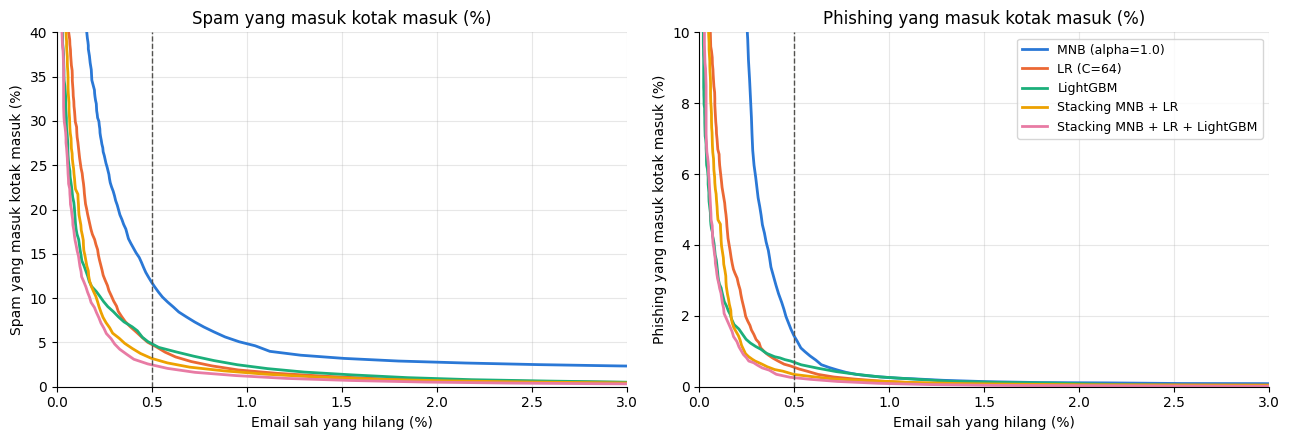

In [14]:
SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']


def ham_margin(log_proba):
    return log_proba[:, 0] - np.max(log_proba[:, 1:], axis=1)


def tradeoff_curve(name, n_points=400):
    margin = ham_margin(cv_results[name]['log_proba'])
    thresholds = np.unique(np.quantile(margin, np.linspace(0, 1, n_points)))
    rows = []
    for t in thresholds:
        kept = margin >= t
        rows.append({
            'ham_lost': (~kept[y_train == 0]).mean() * 100,
            'spam_to_ham': kept[y_train == 2].mean() * 100,
            'phish_to_ham': kept[y_train == 1].mean() * 100,
        })
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for color, name in zip(SERIES_COLORS, FINALISTS):
    curve = tradeoff_curve(name)
    axes[0].plot(curve['ham_lost'], curve['spam_to_ham'], color=color, linewidth=2, label=name)
    axes[1].plot(curve['ham_lost'], curve['phish_to_ham'], color=color, linewidth=2, label=name)
for ax, title in zip(axes, ['Spam yang masuk kotak masuk (%)', 'Phishing yang masuk kotak masuk (%)']):
    ax.axvline((1 - HAM_RECALL_TARGET) * 100, color='#52514e', linestyle='--', linewidth=1)
    ax.set_xlim(0, 3)
    ax.set_xlabel('Email sah yang hilang (%)')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].set_ylim(0, 10)
axes[0].set_ylim(0, 40)
axes[1].legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

## G.3 Model pada Target Ham Recall 99,5%

Untuk setiap finalis, sel berikut mencari nilai $b$ terkecil yang membuat Ham Recall pada seluruh data training minimal 99,5%. Jika threshold bawaan sudah memenuhi target, $b = 0$. Model akhir dipilih dengan aturan B.2: Macro F1 tertinggi pada Ham Recall yang sama.

Nilai $b$ dipilih dari prediksi *out-of-fold* data training, sehingga hasil pada tabel ini sedikit optimistis. Model akhir dan nilai $b$-nya akan diuji ulang pada data testing.

In [15]:
def ham_bias_for_target(name, target=HAM_RECALL_TARGET):
    margin = ham_margin(cv_results[name]['log_proba'])[y_train == 0]
    return max(0.0, -np.quantile(margin, 1 - target, method='lower'))


HAM_BIAS = {name: ham_bias_for_target(name) for name in FINALISTS}
target_rows = []
for name in FINALISTS:
    bias = HAM_BIAS[name]
    scores = per_fold_metrics(name, bias)
    errors = error_counts(y_train, predict_with_ham_bias(cv_results[name]['log_proba'], bias))
    target_rows.append({
        'model': name,
        'b': round(bias, 3),
        'Ham Recall': scores['Ham Recall'].mean(),
        'Macro F1': f"{scores['Macro F1'].mean():.4f} ± {scores['Macro F1'].std(ddof=0):.4f}",
        'Macro F1 (rata-rata)': scores['Macro F1'].mean(),
        'Phish Recall': scores['Phish Recall'].mean(),
        'Phish Precision': scores['Phish Precision'].mean(),
        **errors,
    })
target_table = pd.DataFrame(target_rows)
display(target_table.drop(columns='Macro F1 (rata-rata)').round(4))

FINAL_MODEL = target_table.sort_values('Macro F1 (rata-rata)', ascending=False).iloc[0]['model']
FINAL_BIAS = HAM_BIAS[FINAL_MODEL]
final_row = target_table.set_index('model').loc[FINAL_MODEL]
runner = target_table.sort_values('Macro F1 (rata-rata)', ascending=False).iloc[1]
display(Markdown(
    f"Pada Ham Recall minimal 99,5%, model dengan Macro F1 tertinggi adalah **{FINAL_MODEL}** "
    f"(b = {FINAL_BIAS:.3f}, Macro F1 {final_row['Macro F1 (rata-rata)']:.4f}). "
    f"Model ini kehilangan {final_row['Ham → Spam'] + final_row['Ham → Phish']:,} email sah dari "
    f"{int((y_train == 0).sum()):,}, meloloskan {final_row['Phish → Ham']:,} phishing dan "
    f"{final_row['Spam → Ham']:,} spam ke kotak masuk. "
    f"Model kedua adalah {runner['model']} dengan Macro F1 {runner['Macro F1 (rata-rata)']:.4f}."
))

,model,b,Ham Recall,Macro F1,Phish Recall,Phish Precision,Ham → Spam,Ham → Phish,Phish → Ham,Phish → Spam,Spam → Phish,Spam → Ham
0,MNB (alpha=1.0),15.054,0.995,0.9292 ± 0.0008,0.9507,0.9133,436,74,488,1201,3022,10202
1,LR (C=64),2.455,0.995,0.9612 ± 0.0026,0.9400,0.9627,476,34,184,1873,1215,4070
2,LightGBM,1.597,0.995,0.9709 ± 0.0004,0.9663,0.9777,485,25,237,919,731,4042
3,Stacking MNB + LR,1.767,0.995,0.9677 ± 0.0012,0.9556,0.9553,484,27,118,1403,1506,2768
4,Stacking MNB + LR + LightGBM,1.514,0.995,0.9784 ± 0.0008,0.9718,0.9757,493,18,86,882,813,2146


Pada Ham Recall minimal 99,5%, model dengan Macro F1 tertinggi adalah **Stacking MNB + LR + LightGBM** (b = 1.514, Macro F1 0.9784). Model ini kehilangan 511 email sah dari 102,192, meloloskan 86 phishing dan 2,146 spam ke kotak masuk. Model kedua adalah LightGBM dengan Macro F1 0.9709.

# H. Analisis Kesalahan

Sel berikut menampilkan confusion matrix model terpilih pada target Ham Recall 99,5%, lalu menampilkan contoh pesan untuk dua kesalahan dengan prioritas tertinggi: email sah yang hilang dan phishing yang masuk kotak masuk.

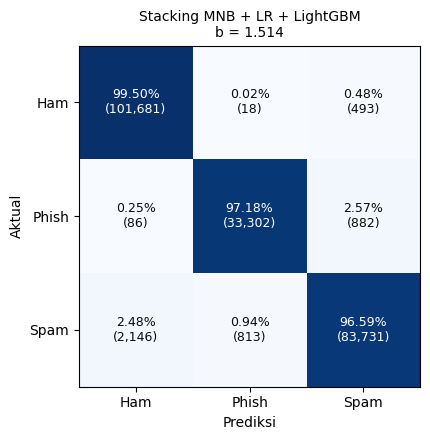

#### Email sah yang hilang (Ham → Spam atau Phish) (511 pesan)

,prediksi,cuplikan teks,jumlah kata
0,Spam,that ' s us .,5
1,Spam,voc ea est eescapenumber recebendo not edcias ...,322
2,Spam,updates debra,2
3,Spam,escapelong nancy riskin,3
4,Phish,subject estce que questions several weeks ago ...,1488
5,Spam,estimados alberto rodrigo deseaba hacer dos pr...,75
6,Spam,i was about to kill myself because of wade not...,15
7,Spam,ladies and gentlemen may i have your attention...,72


#### Phishing yang masuk kotak masuk (Phish → Ham) (86 pesan)

,prediksi,cuplikan teks,jumlah kata
0,Ham,fw real lady caught video would believe bless,8
1,Ham,nan press enter license supporters amended ver...,34
2,Ham,guide thru answers questions laser vision corr...,16
3,Ham,david farber davefarbernet begin forwarded mes...,65
4,Ham,thinking driving condition sir hey vastomazonok,6
5,Ham,security alert confirm national credit union i...,7
6,Ham,10 please use unable see email pleaseclick,7
7,Ham,danny creech southerngent23hotmailcom 7736744s...,154


In [16]:
final_pred = predict_with_ham_bias(cv_results[FINAL_MODEL]['log_proba'], FINAL_BIAS)
counts = confusion_matrix(y_train, final_pred, labels=CLASS_IDS)
row_share = counts / counts.sum(axis=1, keepdims=True)
class_order = [LABEL_NAMES[c] for c in CLASS_IDS]

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(row_share, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{row_share[i, j] * 100:.2f}%\n({counts[i, j]:,})', ha='center', va='center',
                fontsize=9, color='white' if row_share[i, j] > 0.6 else '#0b0b0b')
ax.set_xticks(range(3), class_order)
ax.set_yticks(range(3), class_order)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
ax.set_title(f'{FINAL_MODEL}\nb = {FINAL_BIAS:.3f}', fontsize=10)
plt.tight_layout()
plt.show()


def show_examples(actual, predicted_classes, title, n=8):
    mask = (y_train == actual) & np.isin(final_pred, predicted_classes)
    if not mask.any():
        display(Markdown(f'#### {title}\n\nTidak ada contoh.'))
        return
    index = np.flatnonzero(mask)
    sample = pd.Series(index).sample(n=min(n, len(index)), random_state=RANDOM_STATE).to_numpy()
    display(Markdown(f'#### {title} ({mask.sum():,} pesan)'))
    display(pd.DataFrame({
        'prediksi': [LABEL_NAMES[c] for c in final_pred[sample]],
        'cuplikan teks': X_train.iloc[sample].str.slice(0, 200).to_numpy(),
        'jumlah kata': X_train.iloc[sample].str.count(r'\S+').to_numpy(),
    }))


show_examples(0, [1, 2], 'Email sah yang hilang (Ham → Spam atau Phish)')
show_examples(1, [0], 'Phishing yang masuk kotak masuk (Phish → Ham)')

# I. Temuan dan Keputusan

## I.1 Temuan

Sel berikut merangkum temuan dari seluruh eksperimen.

In [17]:
max_std = max(cv_results[n]['folds']['Macro F1'].std(ddof=0) for n in FINALISTS)
findings = f'''
1. **Validasi.** Simpangan baku Macro F1 antar fold paling besar {max_std:.4f}, sehingga hasil kelima fold konsisten.
2. **Tuning.** `alpha` terbaik untuk Multinomial Naive Bayes adalah {BEST_ALPHA} dan `C` terbaik untuk Logistic Regression adalah {BEST_C}.
3. **Ketidakseimbangan kelas.** Teknik terpilih: {MNB_TECHNIQUE.lower()} untuk Multinomial Naive Bayes dan {LR_TECHNIQUE.lower()} untuk Logistic Regression. SMOTE membuat Macro F1 Multinomial Naive Bayes {change_text(smote_f1)}. Hipotesis 3 **{'didukung' if balancing_helps else 'tidak didukung'}**.
4. **Ensemble.** {ensemble_text}
5. **Model terpilih.** Pada Ham Recall minimal 99,5%, **{FINAL_MODEL}** memperoleh Macro F1 tertinggi ({final_row['Macro F1 (rata-rata)']:.4f}), dengan {final_row['Phish → Ham']:,} phishing dan {final_row['Spam → Ham']:,} spam masuk kotak masuk.
'''
display(Markdown(findings))


1. **Validasi.** Simpangan baku Macro F1 antar fold paling besar 0.0011, sehingga hasil kelima fold konsisten.
2. **Tuning.** `alpha` terbaik untuk Multinomial Naive Bayes adalah 1.0 dan `C` terbaik untuk Logistic Regression adalah 64.
3. **Ketidakseimbangan kelas.** Teknik terpilih: tanpa penanganan untuk Multinomial Naive Bayes dan tanpa penanganan untuk Logistic Regression. SMOTE membuat Macro F1 Multinomial Naive Bayes turun 0.0070. Hipotesis 3 **tidak didukung**.
4. **Ensemble.** Pada threshold bawaan, Macro F1 tertinggi diperoleh **Stacking MNB + LR + LightGBM** (0.9807). Dibandingkan model tunggal terbaik (LightGBM), stacking terbaik (Stacking MNB + LR + LightGBM) membuat Macro F1 naik 0.0034 dan Ham Recall naik 0.0071.
5. **Model terpilih.** Pada Ham Recall minimal 99,5%, **Stacking MNB + LR + LightGBM** memperoleh Macro F1 tertinggi (0.9784), dengan 86 phishing dan 2,146 spam masuk kotak masuk.


## I.2 Rencana Berikutnya

1. **Pertemuan 6.** Eksplorasi struktur data dengan TruncatedSVD dan K-Means, lalu menguji apakah reduksi dimensi membantu model terpilih.
2. **Pertemuan 7.** Seleksi fitur, *learning curve*, pemeriksaan teks yang hampir sama (*near-duplicate*) antara data latih dan data validasi, serta analisis kesalahan lanjutan.
3. **Evaluasi akhir.** Model terpilih, termasuk nilai $b$, dilatih ulang pada seluruh data training dan diuji satu kali pada data testing.